# Intégration de Python dans Power BI

Ce notebook présente comment utiliser Python pour transformer et visualiser des données dans Power BI. L'intégration de Python permet d'enrichir les capacités de Power BI avec des transformations complexes et des visualisations avancées.

## Prérequis

Avant de commencer, assurez-vous d'avoir :
- Python installé sur votre machine
- Les bibliothèques requises installées

Pour installer les bibliothèques nécessaires :

In [ ]:
# Installation des bibliothèques (à exécuter dans un terminal)
# pip install pandas matplotlib seaborn

## 1. Import des bibliothèques et création des données de test

Commençons par importer les bibliothèques nécessaires et créer un jeu de données fictif similaire à ce que Power BI pourrait importer.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Création d'un DataFrame fictif
dataset = pd.DataFrame({
    "Région": ["Europe", "Asie", "Amérique", "Europe", "Asie"],
    "Ventes": [1000, None, 1500, 2000, 5000],
    "Budget_Publicité": [200, 300, None, 400, 500]
})

print("Dataset initial :")
print(dataset)

Dataset initial :
     Région  Ventes  Budget_Publicité
0    Europe  1000.0             200.0
1      Asie     NaN             300.0
2  Amérique  1500.0               NaN
3    Europe  2000.0             400.0
4      Asie  5000.0             500.0


## 2. Nettoyage et transformation des données

Cette section montre comment nettoyer et transformer les données avec Python dans Power Query. Les transformations incluent :
- Gestion des valeurs manquantes
- Normalisation des données
- Suppression des lignes incomplètes

In [3]:
# Copie du dataset pour les transformations
df_transformed = dataset.copy()

# 1. Remplir les valeurs manquantes dans "Ventes"
df_transformed["Ventes"] = df_transformed["Ventes"].fillna(df_transformed["Ventes"].mean())

# 2. Normalisation des ventes
df_transformed["Ventes_normalisees"] = (
    (df_transformed["Ventes"] - df_transformed["Ventes"].mean()) 
    / df_transformed["Ventes"].std()
)

# 3. Suppression des lignes avec des valeurs manquantes restantes
df_transformed = df_transformed.dropna()

print("Dataset transformé :")
print(df_transformed)

Dataset transformé :
   Région  Ventes  Budget_Publicité  Ventes_normalisees
0  Europe  1000.0             200.0           -0.883541
1    Asie  2375.0             300.0            0.000000
3  Europe  2000.0             400.0           -0.240966
4    Asie  5000.0             500.0            1.686761


## 3. Visualisations Python pour Power BI

Power BI permet d'intégrer des visualisations Python directement dans les rapports. Voici quelques exemples de visualisations couramment utilisées.

### 3.1 Graphique en barres avec Matplotlib

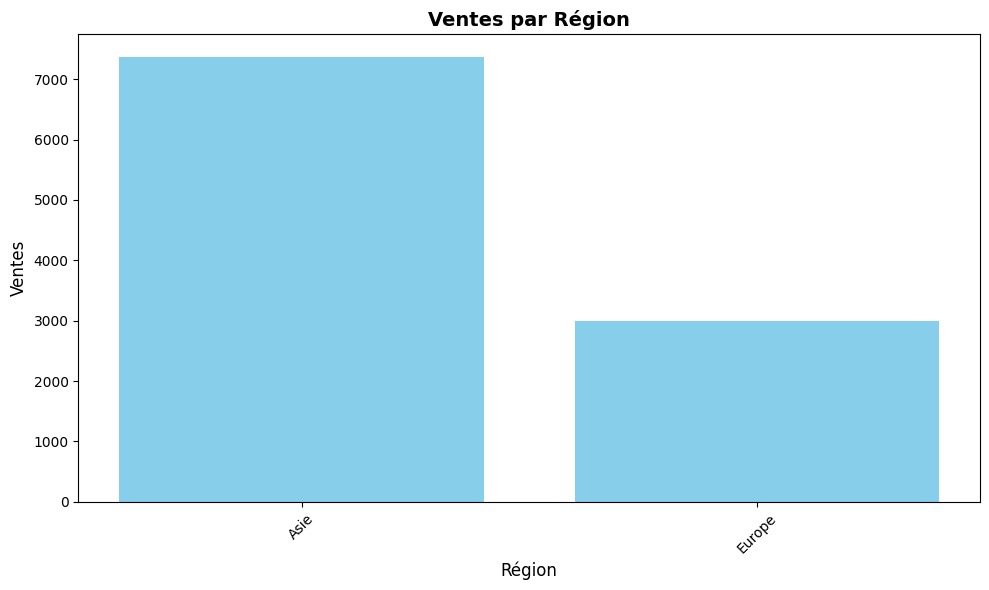

In [4]:
# Configuration de la taille du graphique
plt.figure(figsize=(10, 6))

# Agrégation des ventes par région
ventes_par_region = df_transformed.groupby("Région")["Ventes"].sum()

# Création du graphique en barres
plt.bar(ventes_par_region.index, ventes_par_region.values, color="skyblue")
plt.title("Ventes par Région", fontsize=14, fontweight="bold")
plt.xlabel("Région", fontsize=12)
plt.ylabel("Ventes", fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 3.2 Nuage de points avec Seaborn

Visualisons la relation entre le budget publicitaire et les ventes.

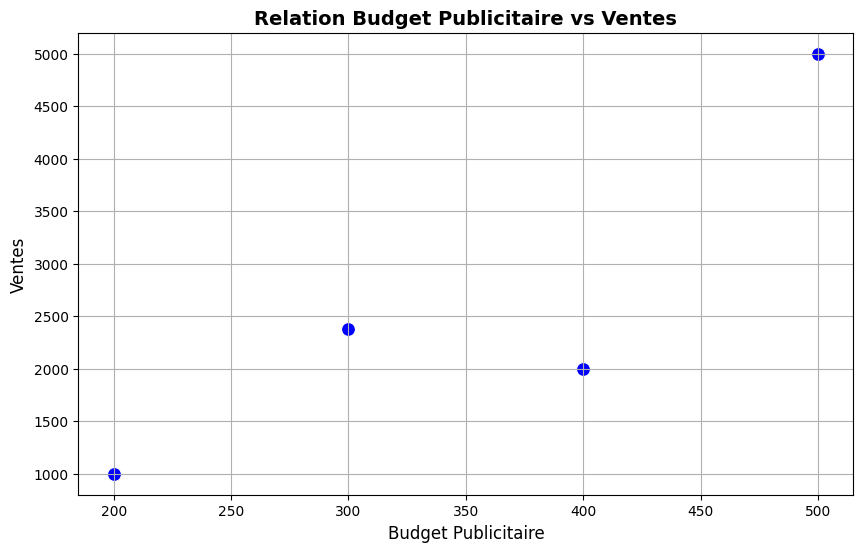

In [5]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x="Budget_Publicité", y="Ventes", data=df_transformed, 
                color="blue", s=100)
plt.title("Relation Budget Publicitaire vs Ventes", fontsize=14, fontweight="bold")
plt.xlabel("Budget Publicitaire", fontsize=12)
plt.ylabel("Ventes", fontsize=12)
plt.grid(True)
plt.show()

### 3.3 Heatmap des corrélations

Visualisons les corrélations entre les variables numériques.

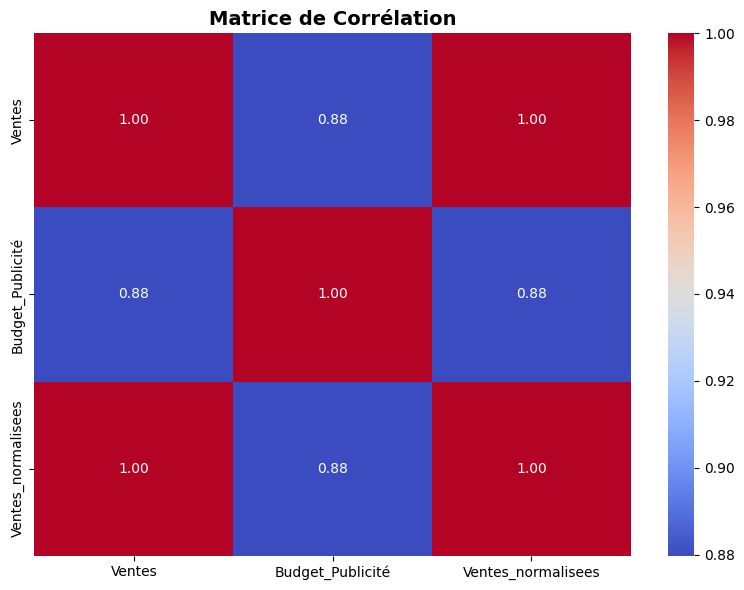

In [6]:
# Sélection des colonnes numériques
numeric_cols = df_transformed.select_dtypes(include=["float64", "int64"]).columns
corr_matrix = df_transformed[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matrice de Corrélation", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## 4. Exercice guidé

Pour mettre en pratique ces concepts dans Power BI :

1. Dans Power Query :
   - Importez vos données
   - Ajoutez une étape de transformation Python
   - Copiez et adaptez le code de nettoyage ci-dessus

2. Dans Power BI :
   - Ajoutez un visuel Python
   - Copiez et adaptez le code des visualisations
   - Personnalisez les graphiques selon vos besoins

Exemple de code à utiliser dans le visuel Python de Power BI :

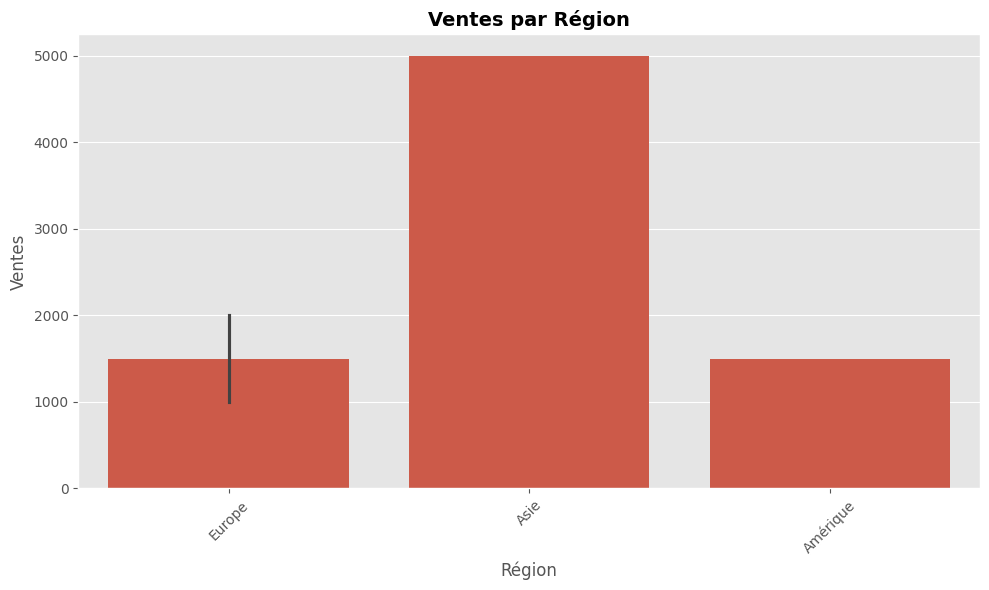

: 

In [ ]:
# Code pour Power BI Visual
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration du style
plt.style.use('ggplot')
plt.figure(figsize=(10, 6))

# Création du graphique (exemple)
sns.barplot(x='Région', y='Ventes', data=dataset)
plt.title('Ventes par Région', fontsize=14, fontweight='bold')
plt.xticks(rotation=45)
plt.tight_layout()

## Conclusion

L'intégration de Python dans Power BI offre de nombreux avantages :

1. Transformations avancées des données avec pandas
2. Visualisations personnalisées avec matplotlib et seaborn
3. Flexibilité accrue dans l'analyse des données

Points clés à retenir :
- Assurez-vous que Python et les bibliothèques nécessaires sont correctement installés
- Testez vos scripts Python séparément avant de les intégrer dans Power BI
- Documentez vos transformations pour faciliter la maintenance
- Optimisez les performances en limitant la quantité de données traitées